# COMPREHENSIVE 5-FOLD CV: ALL MODELS x ALL HP x ALL ENCODERS
# Including CLAM + Full RetNet to isolate contributions
# With Detailed Accuracy Metrics
# 11 Models x 2 Encoders x 5 Folds = 110 Training Runs

---

## METRICS COMPUTED

| Metric | Description |
|--------|-------------|
| **QWK** | Quadratic Weighted Kappa (main metric) |
| **Binary Accuracy** | Cancer (Grade 1-5) vs No Cancer (Grade 0) |
| **Grading Accuracy** | Overall 6-class accuracy |
| **Per-Grade Accuracy** | Accuracy for each grade (0, 1, 2, 3, 4, 5) |
| **Macro F1** | Average F1 across all classes |
| **Per-Grade F1** | F1 for each grade |

---

## COMPARISON MATRIX

| Model | Default HP | Best HP |
|-------|:----------:|:-------:|
| CLAM (Baseline) | Yes | - |
| **CLAM + Full RetNet** | Yes | Yes |
| CLAM-TR | Yes | Yes |
| CLAM-TR + Full RetNet | Yes | Yes |
| CLAM-TR + LayerNorm | Yes | Yes |
| CLAM-TR + Norm+Residual | Yes | Yes |

**x 2 Encoders (UNI, ResNet) = 22 Experiments**

---

## WHY CLAM + Full RetNet?

This isolates contributions:

```
CLAM ------------------> CLAM + Full RetNet
  |                            |
  | (+ Spatial Retention)      | (RetNet alone)
  v                            v
CLAM-TR ---------------> CLAM-TR + Full RetNet
        (+ RetNet)              (Both)
```

## IMPORTS AND SETUP

In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)
from scipy import stats
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## CONFIGURATION

In [2]:
CONFIG = {
    # Paths
    'base_features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',
    'original_checkpoints': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v8_full_comparison/',

    # Encoders
    'encoders': {
        'UNI': {
            'name': 'UNI',
            'features_dir': 'uni',
            'feature_dim': 1024,
        },
        'ResNet': {
            'name': 'ResNet50',
            'features_dir': 'resnet50',
            'feature_dim': 1024,
        },
    },

    # Model
    'hidden_dim': 512,
    'n_classes': 6,
    'patch_size': 256,
    'num_heads': 8,
    'K': 128,

    # Default hyperparameters
    'default_hp': {
        'name': 'Default',
        'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],
        'dropout': 0.25,
        'attention_temperature': 1.0,
        'optimizer': 'adam',
        'use_focal_loss': False,
        'focal_gamma': 2.0,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
    },

    # Best hyperparameters (from category ablation)
    'best_hp': {
        'name': 'Best',
        'gamma_values': [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],
        'dropout': 0.15,
        'attention_temperature': 0.7,
        'optimizer': 'adamw',
        'use_focal_loss': True,
        'focal_gamma': 1.0,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
    },

    # Training
    'epochs': 50,
    'early_stopping_patience': 10,

    # CV
    'n_folds': 5,
    'seed': 42,
}

# Set seeds
import random
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

os.makedirs(CONFIG['results_dir'], exist_ok=True)

Device: cuda


## CHECKPOINT MANAGER

Handles saving/loading progress to resume training after interruption.

In [3]:
import time

class CheckpointManager:
    """Manages checkpoints for resuming training after interruption."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'fold_progress.json')

    def _save_json(self, filepath, data):
        """Save JSON with retry."""
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2)
                return True
            except Exception as e:
                print(f'Save attempt {attempt+1} failed: {e}')
                time.sleep(1)
        return False

    def _load_json(self, filepath):
        """Load JSON safely."""
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    # ========== EXPERIMENT LEVEL ==========

    def get_completed_experiments(self):
        """Get dict of completed experiments."""
        return self._load_json(self.progress_file)

    def is_experiment_completed(self, experiment_name):
        """Check if experiment is completed."""
        return experiment_name in self.get_completed_experiments()

    def save_experiment_result(self, experiment_name, results):
        """Save completed experiment result."""
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)
        print(f'  [Checkpoint] Saved {experiment_name}')

    def load_experiment_result(self, experiment_name):
        """Load experiment result."""
        data = self.get_completed_experiments()
        if experiment_name in data:
            return data[experiment_name]['results']
        return None

    # ========== FOLD LEVEL ==========

    def get_fold_progress(self, experiment_name):
        """Get fold progress for an experiment."""
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        """Save a single fold result."""
        data = self._load_json(self.fold_progress_file)

        if experiment_name not in data:
            data[experiment_name] = {
                'completed_folds': [],
                'fold_results': [],
                'started_at': datetime.now().isoformat()
            }

        # Add fold result
        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({
                'fold': fold_idx,
                'metrics': fold_metrics,
                'completed_at': datetime.now().isoformat()
            })

        data[experiment_name]['last_updated'] = datetime.now().isoformat()
        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        """Clear fold progress after experiment completion."""
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)

    # ========== STATUS ==========

    def get_status(self):
        """Get overall checkpoint status."""
        experiments = self.get_completed_experiments()
        fold_data = self._load_json(self.fold_progress_file)

        return {
            'completed_experiments': len(experiments),
            'in_progress_experiments': len(fold_data),
            'experiment_names': list(experiments.keys()),
            'in_progress_names': list(fold_data.keys())
        }


# Initialize checkpoint manager
checkpoint_manager = CheckpointManager(CONFIG['results_dir'])

# Show status
status = checkpoint_manager.get_status()
print('='*60)
print('CHECKPOINT MANAGER INITIALIZED')
print('='*60)
print(f'Checkpoint directory: {CONFIG["results_dir"]}')
print(f'Completed experiments: {status["completed_experiments"]}')
print(f'In-progress experiments: {status["in_progress_experiments"]}')

if status['completed_experiments'] > 0:
    print(f'\nCompleted:')
    for name in status['experiment_names'][:5]:
        print(f'  - {name}')
    if status['completed_experiments'] > 5:
        print(f'  ... and {status["completed_experiments"] - 5} more')

if status['in_progress_experiments'] > 0:
    print(f'\nIn progress:')
    for name in status['in_progress_names']:
        progress = checkpoint_manager.get_fold_progress(name)
        print(f'  - {name}: {len(progress["completed_folds"])}/5 folds')

print('='*60)

CHECKPOINT MANAGER INITIALIZED
Checkpoint directory: /content/drive/MyDrive/CLAM_TR_Results/v8_full_comparison/
Completed experiments: 22
In-progress experiments: 0

Completed:
  - CLAM_Default_UNI
  - CLAM_FullRetNet_Default_UNI
  - CLAM_FullRetNet_BestHP_UNI
  - CLAMTR_Default_UNI
  - CLAMTR_BestHP_UNI
  ... and 17 more


## DETAILED METRICS COMPUTATION

In [4]:
def compute_detailed_metrics(y_true, y_pred):
    """
    Compute all metrics:
    - QWK
    - Binary accuracy (Cancer vs No Cancer)
    - Grading accuracy (6-class)
    - Per-grade accuracy
    - Per-grade precision, recall, F1
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 1. QWK (main metric)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    # 2. Binary Accuracy: Cancer (Grade 1-5) vs No Cancer (Grade 0)
    y_true_binary = (y_true > 0).astype(int)  # 0 = No Cancer, 1 = Cancer
    y_pred_binary = (y_pred > 0).astype(int)
    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)

    # Binary metrics
    binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

    # 3. Grading Accuracy (6-class overall)
    grading_accuracy = accuracy_score(y_true, y_pred)

    # 4. Per-Grade Metrics
    per_grade_accuracy = {}
    per_grade_precision = {}
    per_grade_recall = {}
    per_grade_f1 = {}
    per_grade_support = {}

    for grade in range(6):
        # Samples of this grade
        mask = (y_true == grade)
        support = mask.sum()
        per_grade_support[grade] = int(support)

        if support > 0:
            # Accuracy for this grade (correct predictions / total samples of this grade)
            per_grade_accuracy[grade] = float((y_pred[mask] == grade).mean())
        else:
            per_grade_accuracy[grade] = 0.0

    # Per-grade precision, recall, F1 using sklearn
    precision_per_class = precision_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)
    recall_per_class = recall_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)
    f1_per_class = f1_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)

    for grade in range(6):
        per_grade_precision[grade] = float(precision_per_class[grade])
        per_grade_recall[grade] = float(recall_per_class[grade])
        per_grade_f1[grade] = float(f1_per_class[grade])

    # 5. Macro and Weighted averages
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # 6. Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=range(6))

    return {
        # Main metrics
        'qwk': qwk,
        'grading_accuracy': grading_accuracy,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,

        # Binary metrics (Cancer vs No Cancer)
        'binary_accuracy': binary_accuracy,
        'binary_precision': binary_precision,
        'binary_recall': binary_recall,
        'binary_f1': binary_f1,

        # Per-grade metrics
        'per_grade_accuracy': per_grade_accuracy,
        'per_grade_precision': per_grade_precision,
        'per_grade_recall': per_grade_recall,
        'per_grade_f1': per_grade_f1,
        'per_grade_support': per_grade_support,

        # Confusion matrix
        'confusion_matrix': cm.tolist(),
    }


def print_detailed_metrics(metrics, model_name="Model"):
    """Pretty print detailed metrics."""

    print(f'\n{"="*70}')
    print(f'DETAILED METRICS: {model_name}')
    print(f'{"="*70}')

    # Main metrics
    print(f'\n--- MAIN METRICS ---')
    print(f'  QWK:              {metrics["qwk"]:.4f}')
    print(f'  Grading Accuracy: {metrics["grading_accuracy"]*100:.2f}%')
    print(f'  Macro F1:         {metrics["macro_f1"]:.4f}')
    print(f'  Weighted F1:      {metrics["weighted_f1"]:.4f}')

    # Binary metrics
    print(f'\n--- BINARY (Cancer vs No Cancer) ---')
    print(f'  Accuracy:   {metrics["binary_accuracy"]*100:.2f}%')
    print(f'  Precision:  {metrics["binary_precision"]:.4f}')
    print(f'  Recall:     {metrics["binary_recall"]:.4f}')
    print(f'  F1 Score:   {metrics["binary_f1"]:.4f}')

    # Per-grade metrics
    print(f'\n--- PER-GRADE METRICS ---')
    print(f'{"Grade":<10} {"Support":>8} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} {"F1":>10}')
    print('-' * 60)

    for grade in range(6):
        support = metrics['per_grade_support'][grade]
        acc = metrics['per_grade_accuracy'][grade]
        prec = metrics['per_grade_precision'][grade]
        rec = metrics['per_grade_recall'][grade]
        f1 = metrics['per_grade_f1'][grade]

        print(f'Grade {grade:<4} {support:>8} {acc*100:>9.2f}% {prec:>10.4f} {rec:>10.4f} {f1:>10.4f}')

    print('=' * 70)

## MODEL CONFIGURATIONS (11 per encoder)

In [5]:
def get_model_configs():
    """Generate all model configurations."""

    configs = {}

    # 1. CLAM (Default only - baseline)
    configs['CLAM_Default'] = {
        'name': 'CLAM',
        'model_type': 'CLAM',
        'hp_type': 'default',
    }

    # 2. CLAM + Full RetNet (Default) - NEW!
    configs['CLAM_FullRetNet_Default'] = {
        'name': 'CLAM + Full RetNet',
        'model_type': 'CLAM_RetNet',
        'hp_type': 'default',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': True,
        'gate_type': 'swish',
        'use_retention_ffn': True,
        'ffn_expansion': 4,
    }

    # 3. CLAM + Full RetNet (Best) - NEW!
    configs['CLAM_FullRetNet_BestHP'] = {
        'name': 'CLAM + Full RetNet',
        'model_type': 'CLAM_RetNet',
        'hp_type': 'best',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': True,
        'gate_type': 'swish',
        'use_retention_ffn': True,
        'ffn_expansion': 4,
    }

    # 4. CLAM-TR (Default)
    configs['CLAMTR_Default'] = {
        'name': 'CLAM-TR',
        'model_type': 'CLAM_TR',
        'hp_type': 'default',
    }

    # 5. CLAM-TR (Best HP)
    configs['CLAMTR_BestHP'] = {
        'name': 'CLAM-TR',
        'model_type': 'CLAM_TR',
        'hp_type': 'best',
    }

    # 6. CLAM-TR + Full RetNet (Default)
    configs['CLAMTR_FullRetNet_Default'] = {
        'name': 'CLAM-TR + Full RetNet',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'default',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': True,
        'gate_type': 'swish',
        'use_retention_ffn': True,
        'ffn_expansion': 4,
    }

    # 7. CLAM-TR + Full RetNet (Best HP)
    configs['CLAMTR_FullRetNet_BestHP'] = {
        'name': 'CLAM-TR + Full RetNet',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'best',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': True,
        'gate_type': 'swish',
        'use_retention_ffn': True,
        'ffn_expansion': 4,
    }

    # 8. CLAM-TR + LayerNorm (Default)
    configs['CLAMTR_LayerNorm_Default'] = {
        'name': 'CLAM-TR + LayerNorm',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'default',
        'use_retention_norm': True,
        'norm_type': 'layer',
        'use_retention_residual': False,
        'use_retention_gate': False,
        'use_retention_ffn': False,
    }

    # 9. CLAM-TR + LayerNorm (Best HP)
    configs['CLAMTR_LayerNorm_BestHP'] = {
        'name': 'CLAM-TR + LayerNorm',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'best',
        'use_retention_norm': True,
        'norm_type': 'layer',
        'use_retention_residual': False,
        'use_retention_gate': False,
        'use_retention_ffn': False,
    }

    # 10. CLAM-TR + Norm+Residual (Default)
    configs['CLAMTR_NormRes_Default'] = {
        'name': 'CLAM-TR + Norm+Res',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'default',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': False,
        'use_retention_ffn': False,
    }

    # 11. CLAM-TR + Norm+Residual (Best HP)
    configs['CLAMTR_NormRes_BestHP'] = {
        'name': 'CLAM-TR + Norm+Res',
        'model_type': 'CLAM_TR_RetNet',
        'hp_type': 'best',
        'use_retention_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_retention_residual': True,
        'use_retention_gate': False,
        'use_retention_ffn': False,
    }

    return configs

MODEL_CONFIGS = get_model_configs()

print(f'Model configurations: {len(MODEL_CONFIGS)}')
print(f'Encoders: {list(CONFIG["encoders"].keys())}')
print(f'Total experiments: {len(MODEL_CONFIGS) * len(CONFIG["encoders"])}')
print(f'Total training runs: {len(MODEL_CONFIGS) * len(CONFIG["encoders"]) * CONFIG["n_folds"]}')

Model configurations: 11
Encoders: ['UNI', 'ResNet']
Total experiments: 22
Total training runs: 110


## MODEL CLASSES

In [6]:
class GatedAttention(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x, temperature=1.0):
        a = self.attention_a(x)
        b = self.attention_b(x)
        return self.attention_c(a * b).squeeze(-1) / temperature


# ============================================================================
# MODEL 1: CLAM (Baseline - No Spatial Retention, No RetNet)
# ============================================================================

class CLAM(nn.Module):
    """Original CLAM - baseline"""
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords=None, temperature=1.0):
        h = self.feature_transform(x)
        A = F.softmax(self.attention(h, temperature), dim=0)
        M = torch.sum(A.unsqueeze(-1) * h, dim=0)
        return self.classifier(M)


# ============================================================================
# Retention Heads
# ============================================================================

class RetentionHead(nn.Module):
    """Basic retention head (without spatial decay - for CLAM + RetNet)"""
    def __init__(self, hidden_dim, num_heads):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** -0.5

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale
        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V)


class SpatialRetentionHead(nn.Module):
    """Spatial retention head with distance-based decay (for CLAM-TR)"""
    def __init__(self, hidden_dim, gamma, num_heads):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.gamma = gamma
        self.scale = self.head_dim ** -0.5

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        # Distance-based decay
        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)
        normalized = distances / (distances.max() + 1e-6)
        D = self.gamma ** normalized

        scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale * D
        attn = F.softmax(scores, dim=-1)

        return torch.matmul(attn, V)


# ============================================================================
# Retention Modules
# ============================================================================

class SpatialRetention(nn.Module):
    """Spatial retention with distance decay (for CLAM-TR)"""
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

        if len(gamma_values) != num_heads:
            gamma_values = np.linspace(gamma_values[0], gamma_values[-1], num_heads).tolist()

        self.heads = nn.ModuleList([
            SpatialRetentionHead(hidden_dim, gamma_values[i], num_heads)
            for i in range(num_heads)
        ])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x, coords):
        head_outputs = [head(x, coords) for head in self.heads]
        return self.output_proj(torch.cat(head_outputs, dim=-1))


# ============================================================================
# MODEL 2: CLAM-TR (Spatial Retention without RetNet enhancements)
# ============================================================================

class CLAM_TR(nn.Module):
    """CLAM-TR - CLAM + Spatial Retention (your contribution)"""
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25,
                 K=128, num_heads=8, gamma_values=None):
        super().__init__()
        self.K = K

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.spatial_retention = SpatialRetention(hidden_dim, num_heads, gamma_values)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, temperature=1.0):
        h = self.feature_transform(x)

        A = self.attention(h, temperature)
        A_softmax = F.softmax(A, dim=0)

        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)
        M_retention = torch.mean(self.spatial_retention(h_topk, coords_topk), dim=0)

        return self.classifier(M_clam + M_retention)

In [7]:
# ============================================================================
# RetNet Enhancement Components
# ============================================================================

class SwishGate(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class FFNBlock(nn.Module):
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        hidden = dim * expansion
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


# ============================================================================
# Enhanced Retention Module (Can be Basic or Spatial)
# ============================================================================

class RetentionEnhanced(nn.Module):
    """Enhanced retention with RetNet components (can be basic or spatial)"""
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None,
                 use_spatial=False,  # True = CLAM-TR, False = CLAM
                 use_norm=False, norm_type='layer', num_groups=8,
                 use_residual=False, use_gate=False, gate_type='swish',
                 use_ffn=False, ffn_expansion=4, dropout=0.1):
        super().__init__()

        self.use_spatial = use_spatial
        self.use_norm = use_norm
        self.use_residual = use_residual
        self.use_gate = use_gate
        self.use_ffn = use_ffn

        # Retention (basic or spatial)
        if use_spatial:
            if gamma_values is None:
                gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]
            if len(gamma_values) != num_heads:
                gamma_values = np.linspace(gamma_values[0], gamma_values[-1], num_heads).tolist()

            self.heads = nn.ModuleList([
                SpatialRetentionHead(hidden_dim, gamma_values[i], num_heads)
                for i in range(num_heads)
            ])
        else:
            self.heads = nn.ModuleList([
                RetentionHead(hidden_dim, num_heads)
                for _ in range(num_heads)
            ])

        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

        # Normalization
        if use_norm:
            if norm_type == 'layer':
                self.norm = nn.LayerNorm(hidden_dim)
            elif norm_type == 'group':
                self.norm = nn.GroupNorm(num_groups, hidden_dim)

        # Gate
        if use_gate:
            self.gate = SwishGate(hidden_dim)

        # FFN
        if use_ffn:
            self.ffn = FFNBlock(hidden_dim, ffn_expansion, dropout)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, coords=None):
        identity = x

        # Multi-head retention
        if self.use_spatial:
            head_outputs = [head(x, coords) for head in self.heads]
        else:
            head_outputs = [head(x) for head in self.heads]

        out = self.output_proj(torch.cat(head_outputs, dim=-1))
        out = self.dropout(out)

        # RetNet components
        if self.use_norm:
            out = self.norm(out)
        if self.use_residual:
            out = out + identity
        if self.use_gate:
            out = self.gate(out)
        if self.use_ffn:
            out = self.ffn(out)

        return out


# ============================================================================
# MODEL 3: CLAM + RetNet (RetNet WITHOUT Spatial Retention) - NEW!
# ============================================================================

class CLAM_RetNet(nn.Module):
    """CLAM + RetNet (no spatial decay) - to isolate RetNet contribution"""
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25,
                 K=128, num_heads=8, config=None):
        super().__init__()
        self.K = K

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)

        # RetNet WITHOUT spatial decay
        self.retention = RetentionEnhanced(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            use_spatial=False,  # No spatial decay!
            use_norm=config.get('use_retention_norm', False),
            norm_type=config.get('norm_type', 'layer'),
            num_groups=config.get('num_groups', 8),
            use_residual=config.get('use_retention_residual', False),
            use_gate=config.get('use_retention_gate', False),
            gate_type=config.get('gate_type', 'swish'),
            use_ffn=config.get('use_retention_ffn', False),
            ffn_expansion=config.get('ffn_expansion', 4),
            dropout=dropout
        )

        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, temperature=1.0):
        h = self.feature_transform(x)

        A = self.attention(h, temperature)
        A_softmax = F.softmax(A, dim=0)

        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # RetNet aggregation (no coords used - no spatial decay)
        M_retention = torch.mean(self.retention(h_topk), dim=0)

        return self.classifier(M_clam + M_retention)


# ============================================================================
# MODEL 4: CLAM-TR + RetNet (Spatial Retention WITH RetNet enhancements)
# ============================================================================

class CLAM_TR_RetNet(nn.Module):
    """CLAM-TR + RetNet - Full model with spatial retention and RetNet"""
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25,
                 K=128, num_heads=8, gamma_values=None, config=None):
        super().__init__()
        self.K = K

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)

        # Spatial Retention WITH RetNet enhancements
        self.spatial_retention = RetentionEnhanced(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            gamma_values=gamma_values,
            use_spatial=True,  # With spatial decay!
            use_norm=config.get('use_retention_norm', False),
            norm_type=config.get('norm_type', 'layer'),
            num_groups=config.get('num_groups', 8),
            use_residual=config.get('use_retention_residual', False),
            use_gate=config.get('use_retention_gate', False),
            gate_type=config.get('gate_type', 'swish'),
            use_ffn=config.get('use_retention_ffn', False),
            ffn_expansion=config.get('ffn_expansion', 4),
            dropout=dropout
        )

        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, temperature=1.0):
        h = self.feature_transform(x)

        A = self.attention(h, temperature)
        A_softmax = F.softmax(A, dim=0)

        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)
        M_retention = torch.mean(self.spatial_retention(h_topk, coords_topk), dim=0)

        return self.classifier(M_clam + M_retention)

## MODEL FACTORY

In [8]:
def create_model(config, feature_dim):
    """Create model with appropriate hyperparameters."""

    hp_type = config.get('hp_type', 'default')
    hp = CONFIG['best_hp'] if hp_type == 'best' else CONFIG['default_hp']

    model_type = config.get('model_type', 'CLAM')

    if model_type == 'CLAM':
        model = CLAM(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=hp['dropout']
        )

    elif model_type == 'CLAM_RetNet':
        model = CLAM_RetNet(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=hp['dropout'],
            K=CONFIG['K'],
            num_heads=CONFIG['num_heads'],
            config=config
        )

    elif model_type == 'CLAM_TR':
        model = CLAM_TR(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=hp['dropout'],
            K=CONFIG['K'],
            num_heads=CONFIG['num_heads'],
            gamma_values=hp['gamma_values']
        )

    elif model_type == 'CLAM_TR_RetNet':
        model = CLAM_TR_RetNet(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=hp['dropout'],
            K=CONFIG['K'],
            num_heads=CONFIG['num_heads'],
            gamma_values=hp['gamma_values'],
            config=config
        )

    return model, hp

## DATASET AND LOSS

In [9]:
class PANDADataset(Dataset):
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]

def collate_fn(batch):
    return batch[0]


class FocalLoss(nn.Module):
    def __init__(self, n_classes=6, gamma=1.0, smoothing=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.gamma = gamma
        self.smoothing = smoothing

    def forward(self, pred, target):
        if pred.dim() == 1:
            pred = pred.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        conf = 1.0 - self.smoothing
        smooth = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter_(1, target.unsqueeze(1), 1)
        smooth_target = one_hot * conf + (1 - one_hot) * smooth

        log_probs = F.log_softmax(pred, dim=1)
        probs = torch.exp(log_probs)
        pt = probs.gather(1, target.unsqueeze(1)).squeeze(1)
        focal_weight = (1 - pt) ** self.gamma

        loss = -(smooth_target * log_probs).sum(dim=1)
        loss = loss * focal_weight

        return loss.mean()


class LabelSmoothingLoss(nn.Module):
    def __init__(self, n_classes=6, smoothing=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing

    def forward(self, pred, target):
        if pred.dim() == 1:
            pred = pred.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        conf = 1.0 - self.smoothing
        smooth = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter_(1, target.unsqueeze(1), 1)
        smooth_target = one_hot * conf + (1 - one_hot) * smooth

        log_probs = F.log_softmax(pred, dim=1)
        return -(smooth_target * log_probs).sum(dim=1).mean()


class EarlyStopping:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

## TRAINING FUNCTION

In [10]:
def train_fold(config, train_loader, val_loader, feature_dim, device):
    """Train one fold and return detailed metrics."""

    model, hp = create_model(config, feature_dim)
    model = model.to(device)
    params = sum(p.numel() for p in model.parameters())

    # Loss
    if hp['use_focal_loss']:
        criterion = FocalLoss(CONFIG['n_classes'], hp['focal_gamma'], hp['label_smoothing'])
    else:
        criterion = LabelSmoothingLoss(CONFIG['n_classes'], hp['label_smoothing'])

    # Optimizer
    if hp['optimizer'] == 'adamw':
        optimizer = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['weight_decay'])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=hp['lr'], weight_decay=hp['weight_decay'])

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    attn_temp = hp['attention_temperature']

    best_qwk = -1
    best_state = None
    best_epoch = 0

    for epoch in range(CONFIG['epochs']):
        model.train()
        for feat, coord, label, _ in train_loader:
            feat, coord = feat.to(device), coord.to(device)
            label = torch.tensor(label).to(device)

            optimizer.zero_grad()
            out = model(feat, coord, attn_temp)
            loss = criterion(out, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        scheduler.step()

        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for feat, coord, label, _ in val_loader:
                feat, coord = feat.to(device), coord.to(device)
                out = model(feat, coord, attn_temp)
                preds.append(out.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stop(qwk):
            break

    # Load best model and compute final predictions
    model.load_state_dict(best_state)
    model.eval()

    preds, labels = [], []
    with torch.no_grad():
        for feat, coord, label, _ in val_loader:
            feat, coord = feat.to(device), coord.to(device)
            out = model(feat, coord, attn_temp)
            preds.append(out.argmax().cpu().item())
            labels.append(label)

    # Compute detailed metrics
    detailed_metrics = compute_detailed_metrics(labels, preds)
    detailed_metrics['best_epoch'] = best_epoch
    detailed_metrics['params'] = params

    return detailed_metrics

## 5-FOLD CV FUNCTION

In [11]:
def aggregate_metric(fold_results, key):
    """Aggregate a single metric across folds."""
    values = [r[key] for r in fold_results]
    return {'mean': np.mean(values), 'std': np.std(values), 'values': values}


def aggregate_per_grade(fold_results, key):
    """Aggregate per-grade metrics across folds."""
    result = {}
    for grade in range(6):
        values = [r[key][grade] for r in fold_results]
        result[grade] = {'mean': np.mean(values), 'std': np.std(values), 'values': values}
    return result


def aggregate_confusion_matrix(fold_results):
    """Sum confusion matrices across folds."""
    cms = [np.array(r['confusion_matrix']) for r in fold_results]
    return np.sum(cms, axis=0).tolist()


def run_5fold_cv(config_key, config, encoder_name, encoder_config, experiment_key=None):
    """Run 5-fold CV on a model with specific encoder.

    Args:
        experiment_key: Unique key for checkpoint tracking (e.g., 'clam_sb_uni')
    """

    hp_type = config.get('hp_type', 'default')
    hp_name = CONFIG['best_hp']['name'] if hp_type == 'best' else CONFIG['default_hp']['name']

    full_name = f"{config['name']} ({hp_name}) - {encoder_name}"

    # Use experiment_key for checkpointing
    if experiment_key is None:
        experiment_key = f"{config_key}_{encoder_name}"

    print(f'\n{"="*70}')
    print(f'5-FOLD CV: {full_name}')
    print(f'{"="*70}')

    # Check for partial fold progress
    fold_progress = checkpoint_manager.get_fold_progress(experiment_key)
    completed_folds = fold_progress.get('completed_folds', [])
    saved_fold_results = fold_progress.get('fold_results', [])

    if completed_folds:
        print(f'  [Resume] Found {len(completed_folds)} completed folds: {completed_folds}')

    # Load data
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['base_features_dir'], encoder_config['features_dir'])

    # Check features exist
    if not os.path.exists(features_dir):
        print(f'ERROR: Features directory not found: {features_dir}')
        return None

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Samples: {len(df)}, Feature dim: {encoder_config["feature_dim"]}')

    if len(df) == 0:
        print('ERROR: No samples found!')
        return None

    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    # Initialize fold_results with saved results
    fold_results = []
    for saved_result in saved_fold_results:
        fold_results.append(saved_result['metrics'])

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        # Skip already completed folds
        if fold in completed_folds:
            print(f'  Fold {fold+1}/{CONFIG["n_folds"]}... [SKIPPED - already completed]')
            continue

        print(f'  Fold {fold+1}/{CONFIG["n_folds"]}...', end=' ', flush=True)

        train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

        train_ds = PANDADataset(train_df['image_id'].tolist(), train_df['isup_grade'].tolist(), features_dir)
        val_ds = PANDADataset(val_df['image_id'].tolist(), val_df['isup_grade'].tolist(), features_dir)

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

        metrics = train_fold(config, train_loader, val_loader, encoder_config['feature_dim'], DEVICE)
        fold_results.append(metrics)

        print(f'QWK={metrics["qwk"]:.4f}, Acc={metrics["grading_accuracy"]*100:.1f}%, BinAcc={metrics["binary_accuracy"]*100:.1f}%')

        # Save fold result immediately after completion
        checkpoint_manager.save_fold_result(experiment_key, fold, metrics)
        print(f'    [Checkpoint] Fold {fold+1} saved')

        torch.cuda.empty_cache()

    # Aggregate all metrics across folds
    results = {
        'config_key': config_key,
        'model_name': config['name'],
        'hp_type': hp_type,
        'encoder': encoder_name,
        'full_name': full_name,
        'params': fold_results[0]['params'],

        # Main metrics (aggregated)
        'qwk': aggregate_metric(fold_results, 'qwk'),
        'grading_accuracy': aggregate_metric(fold_results, 'grading_accuracy'),
        'macro_f1': aggregate_metric(fold_results, 'macro_f1'),
        'weighted_f1': aggregate_metric(fold_results, 'weighted_f1'),

        # Binary metrics (aggregated)
        'binary_accuracy': aggregate_metric(fold_results, 'binary_accuracy'),
        'binary_precision': aggregate_metric(fold_results, 'binary_precision'),
        'binary_recall': aggregate_metric(fold_results, 'binary_recall'),
        'binary_f1': aggregate_metric(fold_results, 'binary_f1'),

        # Per-grade metrics (aggregated)
        'per_grade_accuracy': aggregate_per_grade(fold_results, 'per_grade_accuracy'),
        'per_grade_precision': aggregate_per_grade(fold_results, 'per_grade_precision'),
        'per_grade_recall': aggregate_per_grade(fold_results, 'per_grade_recall'),
        'per_grade_f1': aggregate_per_grade(fold_results, 'per_grade_f1'),
        'per_grade_support': aggregate_per_grade(fold_results, 'per_grade_support'),

        # Aggregated confusion matrix
        'confusion_matrix': aggregate_confusion_matrix(fold_results),

        # Raw fold results for reference
        'fold_results': fold_results,

        # Legacy format (for backward compatibility)
        'fold_qwk': [r['qwk'] for r in fold_results],
        'fold_acc': [r['grading_accuracy'] for r in fold_results],
        'fold_f1': [r['macro_f1'] for r in fold_results],
        'mean_qwk': np.mean([r['qwk'] for r in fold_results]),
        'std_qwk': np.std([r['qwk'] for r in fold_results]),
        'mean_acc': np.mean([r['grading_accuracy'] for r in fold_results]),
        'std_acc': np.std([r['grading_accuracy'] for r in fold_results]),
        'mean_f1': np.mean([r['macro_f1'] for r in fold_results]),
        'std_f1': np.std([r['macro_f1'] for r in fold_results]),
    }

    print(f'  Result: QWK={results["mean_qwk"]:.4f} ± {results["std_qwk"]:.4f}')
    print(f'          Grading Acc={results["grading_accuracy"]["mean"]*100:.2f}% ± {results["grading_accuracy"]["std"]*100:.2f}%')
    print(f'          Binary Acc={results["binary_accuracy"]["mean"]*100:.2f}% ± {results["binary_accuracy"]["std"]*100:.2f}%')

    # Clear fold progress since experiment is complete
    checkpoint_manager.clear_fold_progress(experiment_key)

    return results

## MAIN EXECUTION

In [12]:
print('='*70)
print('COMPREHENSIVE 5-FOLD CV: ALL MODELS × ALL HP × ALL ENCODERS')
print('='*70)
print(f'Models: {len(MODEL_CONFIGS)}')
print(f'Encoders: {list(CONFIG["encoders"].keys())}')
print(f'Total experiments: {len(MODEL_CONFIGS) * len(CONFIG["encoders"])}')
print(f'Total training runs: {len(MODEL_CONFIGS) * len(CONFIG["encoders"]) * CONFIG["n_folds"]}')
print('='*70)

# Show checkpoint status
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['completed_experiments'] > 0:
    print(f'  Completed: {status["experiment_names"]}')
if status['in_progress_experiments'] > 0:
    print(f'  In-progress: {status["in_progress_names"]}')
print('='*70)

all_results = {}
experiment_count = 0
skipped_count = 0
total_experiments = len(MODEL_CONFIGS) * len(CONFIG["encoders"])

for encoder_key, encoder_config in CONFIG['encoders'].items():
    print(f'\n{"#"*70}')
    print(f'# ENCODER: {encoder_config["name"]}')
    print(f'{"#"*70}')

    for config_key, config in MODEL_CONFIGS.items():
        experiment_count += 1

        result_key = f'{config_key}_{encoder_key}'

        # Check if experiment is already completed
        if checkpoint_manager.is_experiment_completed(result_key):
            print(f'\n[SKIP] {result_key} - already completed')
            # Load saved results
            saved_result = checkpoint_manager.load_experiment_result(result_key)
            if saved_result:
                all_results[result_key] = saved_result
            skipped_count += 1
            print(f'Progress: {experiment_count}/{total_experiments} ({experiment_count/total_experiments*100:.1f}%) [Skipped: {skipped_count}]')
            continue

        results = run_5fold_cv(config_key, config, encoder_key, encoder_config, experiment_key=result_key)

        if results:
            all_results[result_key] = results
            # Save experiment result via checkpoint manager
            checkpoint_manager.save_experiment_result(result_key, results)

        # Save intermediate results
        with open(os.path.join(CONFIG['results_dir'], 'all_results.json'), 'w') as f:
            json.dump(all_results, f, indent=2)

        print(f'Progress: {experiment_count}/{total_experiments} ({experiment_count/total_experiments*100:.1f}%) [Skipped: {skipped_count}]')

print(f'\n{"="*70}')
print(f'COMPLETED: {total_experiments - skipped_count} experiments run, {skipped_count} skipped (loaded from checkpoint)')
print(f'{"="*70}')

COMPREHENSIVE 5-FOLD CV: ALL MODELS × ALL HP × ALL ENCODERS
Models: 11
Encoders: ['UNI', 'ResNet']
Total experiments: 22
Total training runs: 110

[Checkpoint Status]
  Completed experiments: 22
  In-progress experiments: 0
  Completed: ['CLAM_Default_UNI', 'CLAM_FullRetNet_Default_UNI', 'CLAM_FullRetNet_BestHP_UNI', 'CLAMTR_Default_UNI', 'CLAMTR_BestHP_UNI', 'CLAMTR_FullRetNet_Default_UNI', 'CLAMTR_FullRetNet_BestHP_UNI', 'CLAMTR_LayerNorm_Default_UNI', 'CLAMTR_LayerNorm_BestHP_UNI', 'CLAMTR_NormRes_Default_UNI', 'CLAMTR_NormRes_BestHP_UNI', 'CLAM_Default_ResNet', 'CLAM_FullRetNet_Default_ResNet', 'CLAM_FullRetNet_BestHP_ResNet', 'CLAMTR_Default_ResNet', 'CLAMTR_BestHP_ResNet', 'CLAMTR_FullRetNet_Default_ResNet', 'CLAMTR_FullRetNet_BestHP_ResNet', 'CLAMTR_LayerNorm_Default_ResNet', 'CLAMTR_LayerNorm_BestHP_ResNet', 'CLAMTR_NormRes_Default_ResNet', 'CLAMTR_NormRes_BestHP_ResNet']

######################################################################
# ENCODER: UNI
####################

## RESULTS BY ENCODER

In [13]:
print('\n' + '='*120)
print('RESULTS BY ENCODER')
print('='*120)

for encoder_key in CONFIG['encoders'].keys():
    print(f'\n{"="*60}')
    print(f'ENCODER: {encoder_key}')
    print(f'{"="*60}')
    print(f'{"Model":<30} {"HP":<10} {"QWK":<20} {"Accuracy":<20} {"Params":>12}')
    print('-'*100)

    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    sorted_results = sorted(encoder_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True)

    for key, r in sorted_results:
        hp_type = "Best" if r['hp_type'] == 'best' else "Default"
        qwk_str = f"{r['mean_qwk']:.4f} \u00b1 {r['std_qwk']:.4f}"
        acc_str = f"{r['mean_acc']:.4f} \u00b1 {r['std_acc']:.4f}"
        print(f'{r["model_name"]:<30} {hp_type:<10} {qwk_str:<20} {acc_str:<20} {r["params"]:>12,}')


RESULTS BY ENCODER

ENCODER: UNI
Model                          HP         QWK                  Accuracy                   Params
----------------------------------------------------------------------------------------------------
CLAM + Full RetNet             Best       0.8761 ± 0.0169      0.6267 ± 0.0193         4,204,295
CLAM-TR + Full RetNet          Best       0.8714 ± 0.0326      0.6267 ± 0.0286         4,204,295
CLAM-TR                        Default    0.8688 ± 0.0327      0.6083 ± 0.0405         1,839,879
CLAM-TR + Full RetNet          Default    0.8686 ± 0.0323      0.6333 ± 0.0553         4,204,295
CLAM + Full RetNet             Default    0.8685 ± 0.0239      0.6633 ± 0.0352         4,204,295
CLAM-TR                        Best       0.8654 ± 0.0372      0.6400 ± 0.0487         1,839,879
CLAM-TR + Norm+Res             Default    0.8630 ± 0.0177      0.6183 ± 0.0162         1,840,903
CLAM-TR + LayerNorm            Best       0.8557 ± 0.0237      0.5883 ± 0.0187         1,

## COMPARISON: UNI vs ResNet

In [14]:
print('\n' + '='*120)
print('COMPARISON: UNI vs ResNet (Same Model, Same HP)')
print('='*120)
print(f'{"Model":<30} {"HP":<10} {"UNI QWK":<18} {"ResNet QWK":<18} {"Difference":<12}')
print('-'*100)

for config_key in MODEL_CONFIGS.keys():
    uni_key = f'{config_key}_UNI'
    resnet_key = f'{config_key}_ResNet'

    if uni_key in all_results and resnet_key in all_results:
        uni_r = all_results[uni_key]
        resnet_r = all_results[resnet_key]

        hp_type = "Best" if uni_r['hp_type'] == 'best' else "Default"
        uni_qwk = f"{uni_r['mean_qwk']:.4f} \u00b1 {uni_r['std_qwk']:.4f}"
        resnet_qwk = f"{resnet_r['mean_qwk']:.4f} \u00b1 {resnet_r['std_qwk']:.4f}"
        diff = uni_r['mean_qwk'] - resnet_r['mean_qwk']
        diff_str = f"{diff:+.4f}"

        print(f'{uni_r["model_name"]:<30} {hp_type:<10} {uni_qwk:<18} {resnet_qwk:<18} {diff_str:<12}')


COMPARISON: UNI vs ResNet (Same Model, Same HP)
Model                          HP         UNI QWK            ResNet QWK         Difference  
----------------------------------------------------------------------------------------------------
CLAM                           Default    0.8482 ± 0.0221    0.6661 ± 0.0640    +0.1822     
CLAM + Full RetNet             Default    0.8685 ± 0.0239    0.6824 ± 0.0572    +0.1861     
CLAM + Full RetNet             Best       0.8761 ± 0.0169    0.7150 ± 0.0448    +0.1611     
CLAM-TR                        Default    0.8688 ± 0.0327    0.7338 ± 0.0285    +0.1350     
CLAM-TR                        Best       0.8654 ± 0.0372    0.7082 ± 0.0472    +0.1572     
CLAM-TR + Full RetNet          Default    0.8686 ± 0.0323    0.6707 ± 0.0600    +0.1979     
CLAM-TR + Full RetNet          Best       0.8714 ± 0.0326    0.7121 ± 0.0213    +0.1593     
CLAM-TR + LayerNorm            Default    0.8536 ± 0.0430    0.6175 ± 0.0244    +0.2361     
CLAM-TR + Lay

## BEST MODELS SUMMARY

In [15]:
print('\n' + '='*100)
print('BEST MODEL PER ENCODER')
print('='*100)

for encoder_key in CONFIG['encoders'].keys():
    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    if encoder_results:
        best = max(encoder_results.items(), key=lambda x: x[1]['mean_qwk'])
        r = best[1]
        print(f'\n{encoder_key}:')
        print(f'  Model:    {r["model_name"]} ({r["hp_type"]})')
        print(f'  QWK:      {r["mean_qwk"]:.4f} \u00b1 {r["std_qwk"]:.4f}')
        print(f'  Accuracy: {r["mean_acc"]*100:.2f}% \u00b1 {r["std_acc"]*100:.2f}%')
        print(f'  Params:   {r["params"]:,}')


BEST MODEL PER ENCODER

UNI:
  Model:    CLAM + Full RetNet (best)
  QWK:      0.8761 ± 0.0169
  Accuracy: 62.67% ± 1.93%
  Params:   4,204,295

ResNet:
  Model:    CLAM-TR (default)
  QWK:      0.7338 ± 0.0285
  Accuracy: 50.17% ± 3.35%
  Params:   1,839,879


## STATISTICAL SIGNIFICANCE: Default vs Best HP

In [16]:
print('\n' + '='*100)
print('STATISTICAL TEST: Default HP vs Best HP (Paired t-test)')
print('='*100)

for encoder_key in CONFIG['encoders'].keys():
    print(f'\n--- {encoder_key} ---')
    print(f'{"Model":<30} {"\u0394 QWK":>10} {"t-stat":>10} {"p-value":>10} {"Sig?":>8}')
    print('-'*70)

    for base_config in ['CLAMTR', 'CLAMTR_FullRetNet', 'CLAMTR_LayerNorm', 'CLAMTR_NormRes']:
        default_key = f'{base_config}_Default_{encoder_key}'
        best_key = f'{base_config}_BestHP_{encoder_key}'

        if default_key in all_results and best_key in all_results:
            default_r = all_results[default_key]
            best_r = all_results[best_key]

            t_stat, p_val = stats.ttest_rel(best_r['fold_qwk'], default_r['fold_qwk'])
            diff = best_r['mean_qwk'] - default_r['mean_qwk']
            sig = "\u2713" if p_val < 0.05 else ""

            model_name = default_r['model_name']
            print(f'{model_name:<30} {diff:>+10.4f} {t_stat:>10.4f} {p_val:>10.4f} {sig:>8}')


STATISTICAL TEST: Default HP vs Best HP (Paired t-test)

--- UNI ---
Model                               Δ QWK     t-stat    p-value     Sig?
----------------------------------------------------------------------
CLAM-TR                           -0.0033    -0.1812     0.8650         
CLAM-TR + Full RetNet             +0.0029     0.4195     0.6964         
CLAM-TR + LayerNorm               +0.0021     0.1285     0.9039         
CLAM-TR + Norm+Res                -0.0074    -0.9776     0.3836         

--- ResNet ---
Model                               Δ QWK     t-stat    p-value     Sig?
----------------------------------------------------------------------
CLAM-TR                           -0.0256    -1.2593     0.2764         
CLAM-TR + Full RetNet             +0.0415     1.4122     0.2307         
CLAM-TR + LayerNorm               +0.0233     1.1356     0.3195         
CLAM-TR + Norm+Res                +0.0413     1.8060     0.1452         


## VISUALIZATION

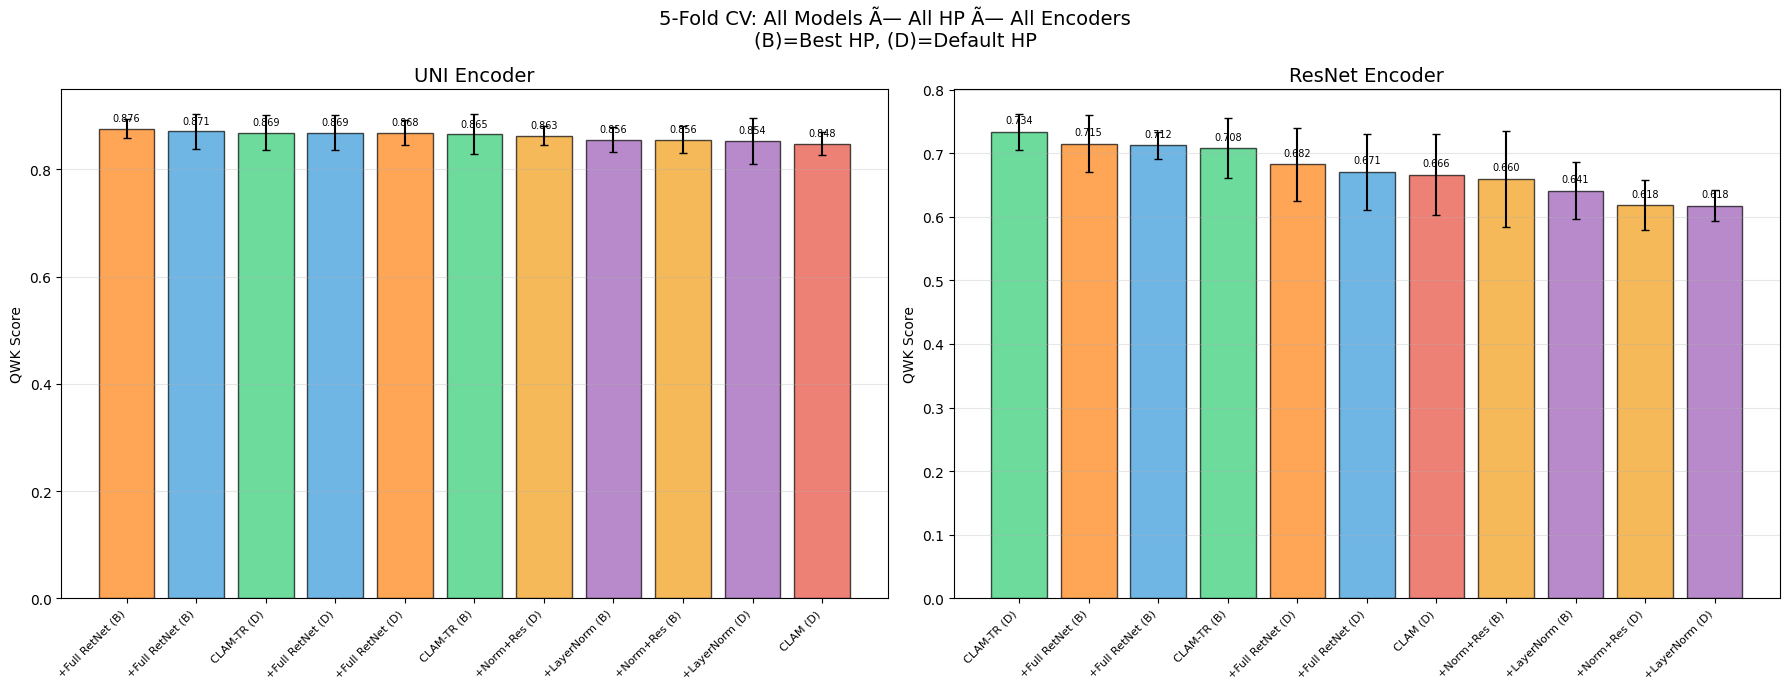

In [17]:
# Create figure with subplots for each encoder
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

color_map = {
    'CLAM': '#e74c3c',
    'CLAM + Full RetNet': '#ff7f0e',
    'CLAM-TR': '#2ecc71',
    'CLAM-TR + Full RetNet': '#3498db',
    'CLAM-TR + LayerNorm': '#9b59b6',
    'CLAM-TR + Norm+Res': '#f39c12',
}

for idx, encoder_key in enumerate(CONFIG['encoders'].keys()):
    ax = axes[idx]

    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    sorted_results = sorted(encoder_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True)

    names = []
    means = []
    stds = []
    colors = []

    for key, r in sorted_results:
        hp_label = "(B)" if r['hp_type'] == 'best' else "(D)"
        short_name = r['model_name'].replace('CLAM-TR + ', '+').replace('CLAM + ', '+')
        names.append(f"{short_name} {hp_label}")
        means.append(r['mean_qwk'])
        stds.append(r['std_qwk'])
        colors.append(color_map.get(r['model_name'], '#95a5a6'))

    bars = ax.bar(range(len(names)), means, yerr=stds, capsize=3, color=colors, alpha=0.7, edgecolor='black')
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('QWK Score')
    ax.set_title(f'{encoder_key} Encoder', fontsize=14)
    ax.grid(axis='y', alpha=0.3)

    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{mean:.3f}', ha='center', va='bottom', fontsize=7)

plt.suptitle('5-Fold CV: All Models Ã— All HP Ã— All Encoders\n(B)=Best HP, (D)=Default HP', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'comprehensive_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## PER-GRADE ACCURACY HEATMAP

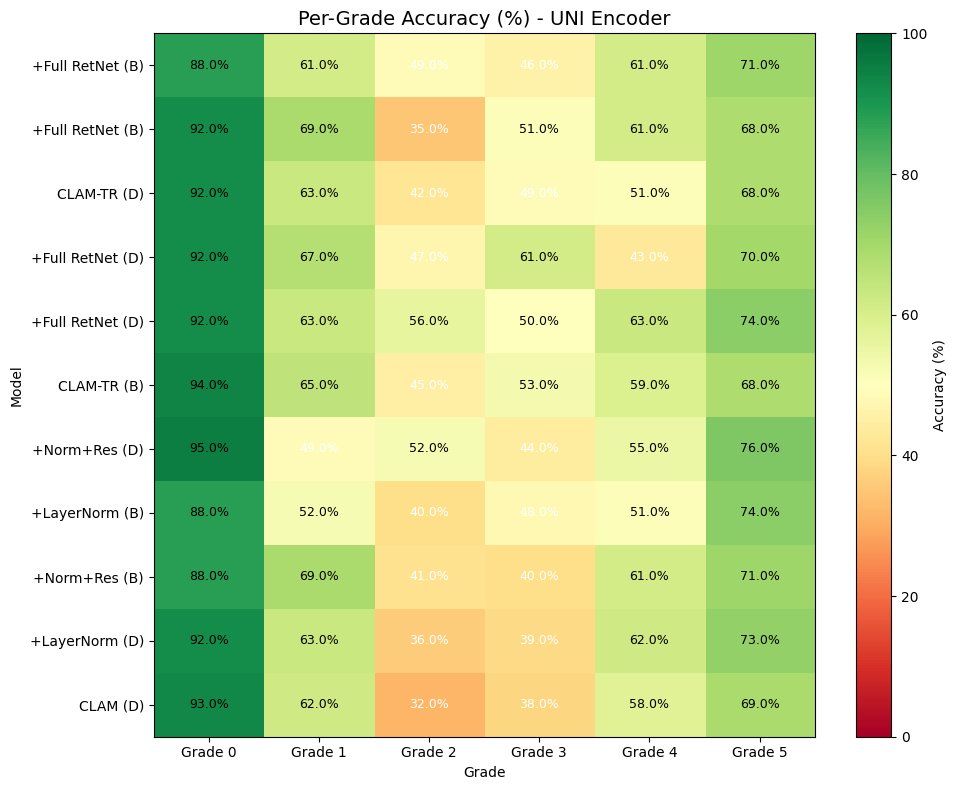

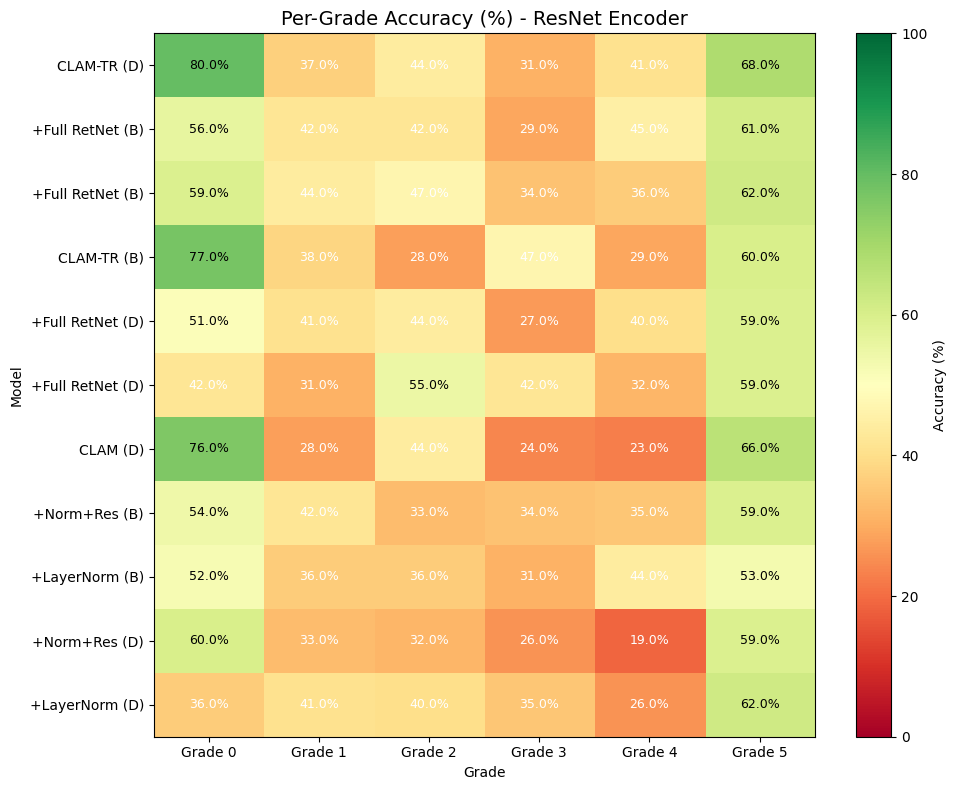


DETAILED PER-GRADE ACCURACY

ENCODER: UNI

Model                     HP               G0           G1           G2           G3           G4           G5 
---------------------------------------------------------------------------------------------------------
CLAM + Full RetNet        B       88.0+- 5.1  61.0+-13.2  49.0+- 3.7  46.0+-15.9  61.0+-10.2  71.0+-12.0 
CLAM-TR + Full RetNet     B       92.0+- 6.8  69.0+-19.3  35.0+-19.7  51.0+-14.6  61.0+-19.6  68.0+-15.7 
CLAM-TR                   D       92.0+- 2.4  63.0+-19.1  42.0+-15.0  49.0+-27.1  51.0+-10.7  68.0+- 9.3 
CLAM-TR + Full RetNet     D       92.0+- 5.1  67.0+- 6.8  47.0+-19.1  61.0+-11.6  43.0+-15.0  70.0+- 7.1 
CLAM + Full RetNet        D       92.0+- 7.5  63.0+-17.5  56.0+-13.9  50.0+-21.2  63.0+- 4.0  74.0+-12.0 
CLAM-TR                   B       94.0+- 3.7  65.0+-15.5  45.0+-23.0  53.0+-20.6  59.0+-15.0  68.0+-10.3 
CLAM-TR + Norm+Res        D       95.0+- 5.5  49.0+-10.2  52.0+-21.6  44.0+-30.9  55.0+-13.4  76.0+- 6

In [18]:
# Per-Grade Accuracy Heatmap for Best Models
def plot_per_grade_accuracy_heatmap(all_results, encoder_key, save_path=None):
    """Plot per-grade accuracy as a heatmap for all models."""

    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    sorted_results = sorted(encoder_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True)

    # Build data matrix
    model_names = []
    data = []

    for key, r in sorted_results:
        hp_label = "(B)" if r['hp_type'] == 'best' else "(D)"
        short_name = r['model_name'].replace('CLAM-TR + ', '+').replace('CLAM + ', '+')
        model_names.append(f"{short_name} {hp_label}")

        # Handle both int and string keys (JSON converts keys to strings)
        pga = r['per_grade_accuracy']
        row = [pga.get(grade, pga.get(str(grade), {})).get('mean', 0) * 100 for grade in range(6)]
        data.append(row)

    data = np.array(data)

    # Plot
    fig, ax = plt.subplots(figsize=(10, 8))

    im = ax.imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)

    ax.set_xticks(range(6))
    ax.set_xticklabels([f'Grade {i}' for i in range(6)])
    ax.set_yticks(range(len(model_names)))
    ax.set_yticklabels(model_names)

    # Add text annotations
    for i in range(len(model_names)):
        for j in range(6):
            text = ax.text(j, i, f'{data[i, j]:.1f}%',
                          ha='center', va='center', fontsize=9,
                          color='white' if data[i, j] < 50 else 'black')

    ax.set_title(f'Per-Grade Accuracy (%) - {encoder_key} Encoder', fontsize=14)
    ax.set_xlabel('Grade')
    ax.set_ylabel('Model')

    plt.colorbar(im, label='Accuracy (%)')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

# Plot for each encoder
for encoder_key in CONFIG['encoders'].keys():
    save_path = os.path.join(CONFIG['results_dir'], f'per_grade_accuracy_{encoder_key}.png')
    plot_per_grade_accuracy_heatmap(all_results, encoder_key, save_path)


# ============================================================================
# DETAILED PER-GRADE METRICS TABLE
# ============================================================================

print('\n' + '='*120)
print('DETAILED PER-GRADE ACCURACY')
print('='*120)

for encoder_key in CONFIG['encoders'].keys():
    print(f'\n{"="*100}')
    print(f'ENCODER: {encoder_key}')
    print(f'{"="*100}')

    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    sorted_results = sorted(encoder_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True)

    print(f'\n{"Model":<25} {"HP":<6} ', end='')
    for grade in range(6):
        print(f'{"G"+str(grade):>12}', end=' ')
    print()
    print('-' * 105)

    for key, r in sorted_results:
        hp_type = "B" if r['hp_type'] == 'best' else "D"
        short_name = r['model_name'][:23]
        print(f'{short_name:<25} {hp_type:<6} ', end='')

        # Handle both int and string keys
        pga = r['per_grade_accuracy']
        for grade in range(6):
            grade_data = pga.get(grade, pga.get(str(grade), {}))
            acc = grade_data.get('mean', 0) * 100
            std = grade_data.get('std', 0) * 100
            print(f'{acc:5.1f}+-{std:4.1f}', end=' ')
        print()

## CONFUSION MATRIX VISUALIZATION


CONFUSION MATRICES: UNI


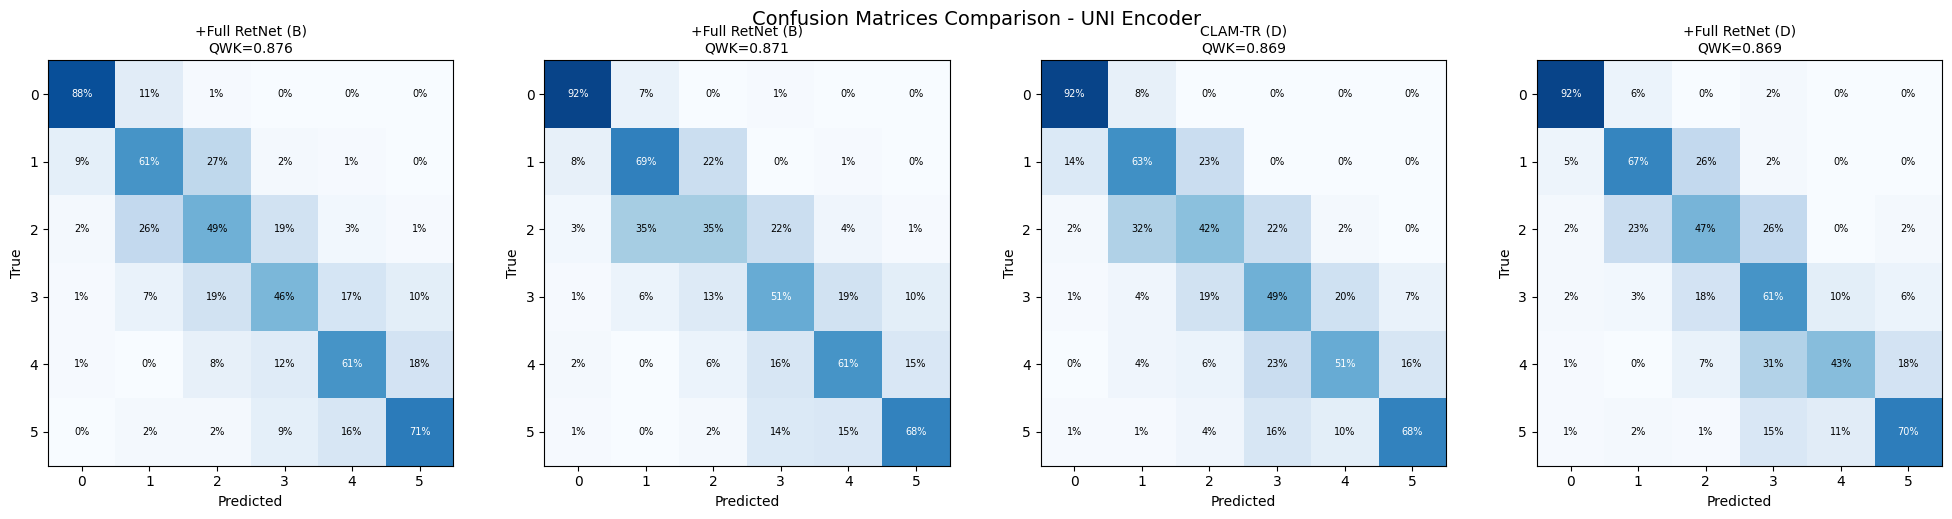


CONFUSION MATRICES: ResNet


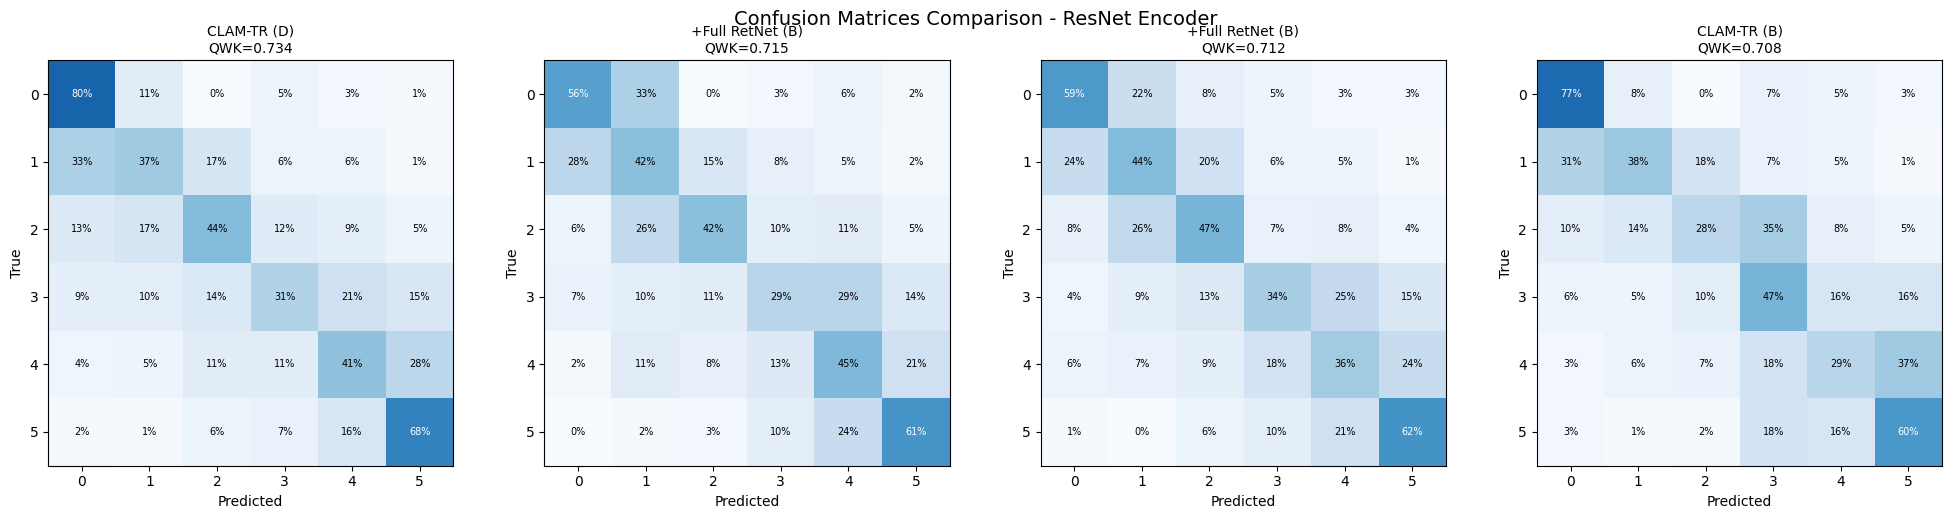


CONFUSION MATRIX: BEST MODEL


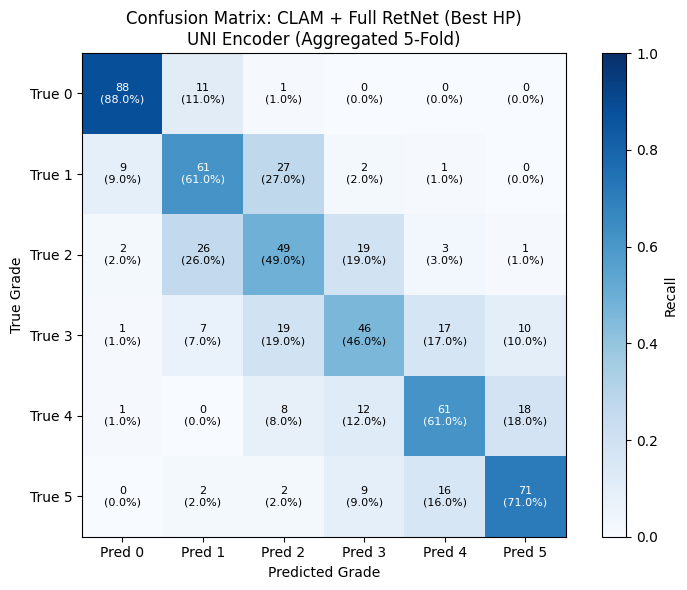

In [19]:
def plot_confusion_matrix(cm, model_name, encoder_key, save_path=None):
    """Plot a single confusion matrix."""
    cm = np.array(cm)

    # Normalize for display (row-wise: recall perspective)
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
    cm_normalized = np.nan_to_num(cm_normalized)  # Handle division by zero

    fig, ax = plt.subplots(figsize=(8, 6))

    im = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)

    ax.set_xticks(range(6))
    ax.set_yticks(range(6))
    ax.set_xticklabels([f'Pred {i}' for i in range(6)])
    ax.set_yticklabels([f'True {i}' for i in range(6)])

    # Add text annotations (show both count and percentage)
    for i in range(6):
        for j in range(6):
            count = cm[i, j]
            pct = cm_normalized[i, j] * 100
            text_color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
            ax.text(j, i, f'{count}\n({pct:.1f}%)',
                   ha='center', va='center', fontsize=8, color=text_color)

    ax.set_title(f'Confusion Matrix: {model_name}\n{encoder_key} Encoder (Aggregated 5-Fold)', fontsize=12)
    ax.set_xlabel('Predicted Grade')
    ax.set_ylabel('True Grade')

    plt.colorbar(im, label='Recall')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


def plot_confusion_matrices_comparison(all_results, encoder_key, model_keys, save_path=None):
    """Plot confusion matrices for multiple models side by side."""
    n_models = len(model_keys)
    fig, axes = plt.subplots(1, n_models, figsize=(5*n_models, 5))

    if n_models == 1:
        axes = [axes]

    for idx, key in enumerate(model_keys):
        if key not in all_results:
            continue

        r = all_results[key]
        cm = np.array(r['confusion_matrix'])
        cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
        cm_normalized = np.nan_to_num(cm_normalized)

        ax = axes[idx]
        im = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)

        ax.set_xticks(range(6))
        ax.set_yticks(range(6))
        ax.set_xticklabels(range(6))
        ax.set_yticklabels(range(6))

        for i in range(6):
            for j in range(6):
                pct = cm_normalized[i, j] * 100
                text_color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
                ax.text(j, i, f'{pct:.0f}%', ha='center', va='center', fontsize=7, color=text_color)

        hp_label = "(B)" if r['hp_type'] == 'best' else "(D)"
        short_name = r['model_name'].replace('CLAM-TR + ', '+').replace('CLAM + ', '+')
        ax.set_title(f'{short_name} {hp_label}\nQWK={r["mean_qwk"]:.3f}', fontsize=10)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')

    plt.suptitle(f'Confusion Matrices Comparison - {encoder_key} Encoder', fontsize=14)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


# Plot confusion matrices for top 4 models per encoder
for encoder_key in CONFIG['encoders'].keys():
    print(f'\n{"="*60}')
    print(f'CONFUSION MATRICES: {encoder_key}')
    print(f'{"="*60}')

    encoder_results = {k: v for k, v in all_results.items() if v['encoder'] == encoder_key}
    sorted_results = sorted(encoder_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True)

    # Get top 4 models
    top_4_keys = [key for key, _ in sorted_results[:4]]

    save_path = os.path.join(CONFIG['results_dir'], f'confusion_matrices_{encoder_key}.png')
    plot_confusion_matrices_comparison(all_results, encoder_key, top_4_keys, save_path)


# Plot confusion matrix for best model overall
print('\n' + '='*60)
print('CONFUSION MATRIX: BEST MODEL')
print('='*60)

best_key = max(all_results.keys(), key=lambda k: all_results[k]['mean_qwk'])
best_r = all_results[best_key]

save_path = os.path.join(CONFIG['results_dir'], 'confusion_matrix_best.png')
plot_confusion_matrix(
    best_r['confusion_matrix'],
    f"{best_r['model_name']} ({'Best' if best_r['hp_type'] == 'best' else 'Default'} HP)",
    best_r['encoder'],
    save_path
)

## CONTRIBUTION ANALYSIS

In [20]:
print('\n' + '='*100)
print('CONTRIBUTION ANALYSIS')
print('='*100)

for encoder_key in CONFIG['encoders'].keys():
    print(f'\n--- {encoder_key} ---')

    # Get relevant results (Best HP for fair comparison)
    clam = all_results.get(f'CLAM_Default_{encoder_key}')
    clam_retnet = all_results.get(f'CLAM_FullRetNet_BestHP_{encoder_key}')
    clam_tr = all_results.get(f'CLAMTR_BestHP_{encoder_key}')
    clam_tr_retnet = all_results.get(f'CLAMTR_FullRetNet_BestHP_{encoder_key}')

    if all([clam, clam_retnet, clam_tr, clam_tr_retnet]):
        print(f'\n  CLAM (baseline):           {clam["mean_qwk"]:.4f} Â± {clam["std_qwk"]:.4f}')
        print(f'  CLAM + Full RetNet:        {clam_retnet["mean_qwk"]:.4f} Â± {clam_retnet["std_qwk"]:.4f}  (RetNet alone: {clam_retnet["mean_qwk"]-clam["mean_qwk"]:+.4f})')
        print(f'  CLAM-TR:                   {clam_tr["mean_qwk"]:.4f} Â± {clam_tr["std_qwk"]:.4f}  (Spatial alone: {clam_tr["mean_qwk"]-clam["mean_qwk"]:+.4f})')
        print(f'  CLAM-TR + Full RetNet:     {clam_tr_retnet["mean_qwk"]:.4f} Â± {clam_tr_retnet["std_qwk"]:.4f}  (Both: {clam_tr_retnet["mean_qwk"]-clam["mean_qwk"]:+.4f})')

        retnet_contrib = clam_retnet["mean_qwk"] - clam["mean_qwk"]
        spatial_contrib = clam_tr["mean_qwk"] - clam["mean_qwk"]
        combined_contrib = clam_tr_retnet["mean_qwk"] - clam["mean_qwk"]
        synergy = combined_contrib - retnet_contrib - spatial_contrib

        print(f'\n  Contributions:')
        print(f'    RetNet components alone:     {retnet_contrib:+.4f} QWK')
        print(f'    Spatial Retention alone:     {spatial_contrib:+.4f} QWK')
        print(f'    Combined (both):             {combined_contrib:+.4f} QWK')
        print(f'    Synergy (combined - sum):    {synergy:+.4f} QWK')
    else:
        print('  Missing results for contribution analysis')


# ============================================================================
# STATISTICAL SIGNIFICANCE vs CLAM Baseline
# ============================================================================

print('\n' + '='*100)
print('STATISTICAL SIGNIFICANCE vs CLAM (Paired t-test)')
print('='*100)

for encoder_key in CONFIG['encoders'].keys():
    print(f'\n--- {encoder_key} ---')

    clam = all_results.get(f'CLAM_Default_{encoder_key}')
    if not clam:
        continue

    clam_qwks = clam['fold_qwk']

    print(f'{"Model":<30} {"Î” QWK":>10} {"t-stat":>10} {"p-value":>10} {"Sig?":>8}')
    print('-'*70)

    for key, r in sorted(all_results.items(), key=lambda x: x[1]['mean_qwk'], reverse=True):
        if r['encoder'] != encoder_key or 'CLAM_Default' in key:
            continue

        t_stat, p_val = stats.ttest_rel(r['fold_qwk'], clam_qwks)
        diff = r['mean_qwk'] - clam['mean_qwk']
        sig = "âœ“" if p_val < 0.05 else ""

        hp_type = "(B)" if r['hp_type'] == 'best' else "(D)"
        name = f"{r['model_name']} {hp_type}"
        print(f'{name:<30} {diff:>+10.4f} {t_stat:>10.4f} {p_val:>10.4f} {sig:>8}')


CONTRIBUTION ANALYSIS

--- UNI ---

  CLAM (baseline):           0.8482 Â± 0.0221
  CLAM + Full RetNet:        0.8761 Â± 0.0169  (RetNet alone: +0.0279)
  CLAM-TR:                   0.8654 Â± 0.0372  (Spatial alone: +0.0172)
  CLAM-TR + Full RetNet:     0.8714 Â± 0.0326  (Both: +0.0232)

  Contributions:
    RetNet components alone:     +0.0279 QWK
    Spatial Retention alone:     +0.0172 QWK
    Combined (both):             +0.0232 QWK
    Synergy (combined - sum):    -0.0218 QWK

--- ResNet ---

  CLAM (baseline):           0.6661 Â± 0.0640
  CLAM + Full RetNet:        0.7150 Â± 0.0448  (RetNet alone: +0.0489)
  CLAM-TR:                   0.7082 Â± 0.0472  (Spatial alone: +0.0421)
  CLAM-TR + Full RetNet:     0.7121 Â± 0.0213  (Both: +0.0460)

  Contributions:
    RetNet components alone:     +0.0489 QWK
    Spatial Retention alone:     +0.0421 QWK
    Combined (both):             +0.0460 QWK
    Synergy (combined - sum):    -0.0450 QWK

STATISTICAL SIGNIFICANCE vs CLAM (Paired t-te

## SAVE FINAL SUMMARY

In [21]:
# Find overall best
overall_best = max(all_results.items(), key=lambda x: x[1]['mean_qwk'])
best_r = overall_best[1]

# Helper to get per-grade data (handles both int and string keys from JSON)
def get_grade_data(per_grade_dict, grade):
    return per_grade_dict.get(grade, per_grade_dict.get(str(grade), {}))

final_summary = {
    'experiment': 'Comprehensive 5-Fold CV (Including CLAM + RetNet) with Detailed Metrics',
    'date': datetime.now().isoformat(),
    'n_folds': CONFIG['n_folds'],
    'encoders': list(CONFIG['encoders'].keys()),
    'models': list(MODEL_CONFIGS.keys()),
    'total_experiments': len(all_results),
    'overall_best': {
        'key': overall_best[0],
        'model': best_r['model_name'],
        'hp_type': best_r['hp_type'],
        'encoder': best_r['encoder'],
        'qwk': f"{best_r['mean_qwk']:.4f} +/- {best_r['std_qwk']:.4f}",
        'grading_accuracy': f"{best_r['grading_accuracy']['mean']*100:.2f}% +/- {best_r['grading_accuracy']['std']*100:.2f}%",
        'binary_accuracy': f"{best_r['binary_accuracy']['mean']*100:.2f}% +/- {best_r['binary_accuracy']['std']*100:.2f}%",
        'macro_f1': f"{best_r['macro_f1']['mean']:.4f} +/- {best_r['macro_f1']['std']:.4f}",
    },
    'contribution_analysis': {},
    'all_results': {}
}

# Add detailed results for each model
for k, v in all_results.items():
    final_summary['all_results'][k] = {
        'model': v['model_name'],
        'hp_type': v['hp_type'],
        'encoder': v['encoder'],
        'params': v['params'],

        # Main metrics
        'mean_qwk': v['mean_qwk'],
        'std_qwk': v['std_qwk'],
        'mean_acc': v['mean_acc'],
        'std_acc': v['std_acc'],
        'grading_accuracy': {'mean': v['grading_accuracy']['mean'], 'std': v['grading_accuracy']['std']},
        'macro_f1': {'mean': v['macro_f1']['mean'], 'std': v['macro_f1']['std']},

        # Binary metrics
        'binary_accuracy': {'mean': v['binary_accuracy']['mean'], 'std': v['binary_accuracy']['std']},
        'binary_precision': {'mean': v['binary_precision']['mean'], 'std': v['binary_precision']['std']},
        'binary_recall': {'mean': v['binary_recall']['mean'], 'std': v['binary_recall']['std']},
        'binary_f1': {'mean': v['binary_f1']['mean'], 'std': v['binary_f1']['std']},

        # Per-grade metrics (mean and std for each grade)
        'per_grade_accuracy': {str(g): {'mean': get_grade_data(v['per_grade_accuracy'], g).get('mean', 0), 'std': get_grade_data(v['per_grade_accuracy'], g).get('std', 0)} for g in range(6)},
        'per_grade_f1': {str(g): {'mean': get_grade_data(v['per_grade_f1'], g).get('mean', 0), 'std': get_grade_data(v['per_grade_f1'], g).get('std', 0)} for g in range(6)},

        # Confusion matrix
        'confusion_matrix': v['confusion_matrix'],

        # Fold values
        'fold_qwk': v['fold_qwk'],
    }

# Contribution analysis per encoder
for encoder_key in CONFIG['encoders'].keys():
    clam = all_results.get(f'CLAM_Default_{encoder_key}')
    clam_retnet = all_results.get(f'CLAM_FullRetNet_BestHP_{encoder_key}')
    clam_tr = all_results.get(f'CLAMTR_BestHP_{encoder_key}')
    clam_tr_retnet = all_results.get(f'CLAMTR_FullRetNet_BestHP_{encoder_key}')

    if all([clam, clam_retnet, clam_tr, clam_tr_retnet]):
        retnet_contrib = clam_retnet["mean_qwk"] - clam["mean_qwk"]
        spatial_contrib = clam_tr["mean_qwk"] - clam["mean_qwk"]
        combined_contrib = clam_tr_retnet["mean_qwk"] - clam["mean_qwk"]
        synergy = combined_contrib - retnet_contrib - spatial_contrib

        final_summary['contribution_analysis'][encoder_key] = {
            'baseline_qwk': clam["mean_qwk"],
            'retnet_alone': retnet_contrib,
            'spatial_alone': spatial_contrib,
            'combined': combined_contrib,
            'synergy': synergy,
        }

# Save to JSON
with open(os.path.join(CONFIG['results_dir'], 'final_summary.json'), 'w') as f:
    json.dump(final_summary, f, indent=2)

# Also save detailed results separately
with open(os.path.join(CONFIG['results_dir'], 'detailed_results.json'), 'w') as f:
    json.dump({k: {
        'model': v['model_name'],
        'hp_type': v['hp_type'],
        'encoder': v['encoder'],
        'qwk': {'mean': v['mean_qwk'], 'std': v['std_qwk']},
        'grading_accuracy': {'mean': v['grading_accuracy']['mean'], 'std': v['grading_accuracy']['std']},
        'binary_accuracy': {'mean': v['binary_accuracy']['mean'], 'std': v['binary_accuracy']['std']},
        'binary_f1': {'mean': v['binary_f1']['mean'], 'std': v['binary_f1']['std']},
        'macro_f1': {'mean': v['macro_f1']['mean'], 'std': v['macro_f1']['std']},
        'per_grade_accuracy': {str(g): {'mean': get_grade_data(v['per_grade_accuracy'], g).get('mean', 0), 'std': get_grade_data(v['per_grade_accuracy'], g).get('std', 0)} for g in range(6)},
        'per_grade_f1': {str(g): {'mean': get_grade_data(v['per_grade_f1'], g).get('mean', 0), 'std': get_grade_data(v['per_grade_f1'], g).get('std', 0)} for g in range(6)},
        'confusion_matrix': v['confusion_matrix'],
    } for k, v in all_results.items()}, f, indent=2)

print(f'\n{"="*70}')
print('FINAL SUMMARY')
print(f'{"="*70}')
print(f'Total experiments: {len(all_results)}')
print(f'\nOVERALL BEST:')
print(f'  Model:          {best_r["model_name"]} ({best_r["hp_type"]})')
print(f'  Encoder:        {best_r["encoder"]}')
print(f'  QWK:            {best_r["mean_qwk"]:.4f} +/- {best_r["std_qwk"]:.4f}')
print(f'  Grading Acc:    {best_r["grading_accuracy"]["mean"]*100:.2f}% +/- {best_r["grading_accuracy"]["std"]*100:.2f}%')
print(f'  Binary Acc:     {best_r["binary_accuracy"]["mean"]*100:.2f}% +/- {best_r["binary_accuracy"]["std"]*100:.2f}%')
print(f'  Macro F1:       {best_r["macro_f1"]["mean"]:.4f} +/- {best_r["macro_f1"]["std"]:.4f}')
print(f'\nPer-Grade Accuracy (Best Model):')
for grade in range(6):
    grade_data = get_grade_data(best_r['per_grade_accuracy'], grade)
    acc = grade_data.get('mean', 0) * 100
    std = grade_data.get('std', 0) * 100
    print(f'  Grade {grade}: {acc:.1f}% +/- {std:.1f}%')
print(f'\nResults saved to: {CONFIG["results_dir"]}')
print('  - all_results.json (intermediate)')
print('  - final_summary.json')
print('  - detailed_results.json')
print('\nDONE!')


FINAL SUMMARY
Total experiments: 22

OVERALL BEST:
  Model:          CLAM + Full RetNet (best)
  Encoder:        UNI
  QWK:            0.8761 +/- 0.0169
  Grading Acc:    62.67% +/- 1.93%
  Binary Acc:     95.83% +/- 0.91%
  Macro F1:       0.6234 +/- 0.0183

Per-Grade Accuracy (Best Model):
  Grade 0: 88.0% +/- 5.1%
  Grade 1: 61.0% +/- 13.2%
  Grade 2: 49.0% +/- 3.7%
  Grade 3: 46.0% +/- 15.9%
  Grade 4: 61.0% +/- 10.2%
  Grade 5: 71.0% +/- 12.0%

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/v8_full_comparison/
  - all_results.json (intermediate)
  - final_summary.json
  - detailed_results.json

DONE!
